# 00 · Python for reaction engineering

A reactor is a mole balance, a rate law and an energy balance solved together, and most of the time the
solution is an ordinary differential equation or a root of an algebraic equation. This notebook sets up the
tools - units, exponentials that span ten orders of magnitude, `scipy` for integrals, roots and ODEs, and the
`engreact` library and its data - with the reaction that will recur throughout the course: an exothermic
first-order reaction A -> B.

**What you will learn**
- work in SI units and convert at the boundaries
- compute Arrhenius rate constants and read an Arrhenius plot
- use quad, brentq and solve_ivp for design integrals, algebraic balances and batch reactors
- read the course data and their provenance

**Before you start:** basic Python  ·  **Time:** about 45 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, optimize
from engreact import datasets, kinetics, thermo
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Units: SI throughout, and why

In [2]:
k = kinetics.arrhenius(5.0e7, 68e3, 320.0)           # 1/s, Ea in J/mol, T in K
print(f"k at 320 K = {k:.3e} 1/s = {k*3600:.3f} 1/h; half-life {np.log(2)/k/60:.1f} min")
C_A0 = 2500.0                                          # mol/m3 = 2.5 mol/L
print(f"C_A0 = {C_A0} mol/m3 = {C_A0/1e3} mol/L; rate at t = 0: {k*C_A0:.3f} mol/(m3 s)")

k at 320 K = 3.975e-04 1/s = 1.431 1/h; half-life 29.1 min
C_A0 = 2500.0 mol/m3 = 2.5 mol/L; rate at t = 0: 0.994 mol/(m3 s)


Every quantity in `engreact` is in SI: moles, metres, seconds, joules, kelvin, pascals. Textbook problems
come in litres, minutes, atmospheres and calories; converting at the boundary (input and output) and computing
in SI inside is the discipline that prevents the factor-of-1000 errors that reactor design is famous for.

## Exponentials and the Arrhenius law

 T (K)  k (1/s)  k / k(300 K)
   280 1.03e-05         0.143
   300 7.23e-05             1
   320 0.000397           5.5
   340  0.00179          24.7
   360   0.0068            94
   380   0.0225           311
   400    0.066           912
   420    0.175      2.41e+03


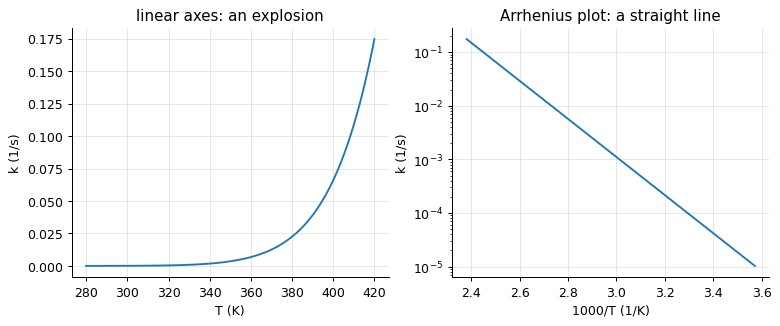

In [3]:
T = np.linspace(280, 420, 8)
k = kinetics.arrhenius(5.0e7, 68e3, T)
print(pd.DataFrame({"T (K)": T, "k (1/s)": k, "k / k(300 K)": k / kinetics.arrhenius(5.0e7, 68e3, 300.0)}).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
Tf = np.linspace(280, 420, 200)
ax[0].plot(Tf, kinetics.arrhenius(5.0e7, 68e3, Tf)); ax[0].set(xlabel="T (K)", ylabel="k (1/s)", title="linear axes: an explosion")
ax[1].semilogy(1000 / Tf, kinetics.arrhenius(5.0e7, 68e3, Tf)); ax[1].set(xlabel="1000/T (1/K)", ylabel="k (1/s)", title="Arrhenius plot: a straight line"); plt.show()

A 140 K rise multiplies the rate by ten thousand. On linear axes that is a wall; against 1/T on a log axis it
is a straight line with slope $-E_a/R$ - the Arrhenius plot that every kineticist draws first, and the reason
temperature is the most powerful and the most dangerous control variable in a reactor.

## Integrals, roots and ODEs

In [4]:
k300 = kinetics.arrhenius(5.0e7, 68e3, 300.0)
# integral: PFR volume for 80 % conversion of a first-order reaction, F_A0 = 1 mol/s, C_A0 = 2500 mol/m3
V_pfr, _ = integrate.quad(lambda X: 1 / (k300 * C_A0 * (1 - X)), 0, 0.8)
print(f"PFR volume for X = 0.8: {V_pfr:.2f} m3 (analytic {-np.log(0.2)/(k300*C_A0):.2f})")
# root: the CSTR conversion for the same volume
X_cstr = optimize.brentq(lambda X: X / (k300 * C_A0 * (1 - X)) - V_pfr, 0, 0.999)
print(f"a CSTR of the same volume gives X = {X_cstr:.3f}")
# ODE: batch reactor
sol = integrate.solve_ivp(lambda t, C: [-k300 * C[0]], (0, 7200), [C_A0], t_eval=np.linspace(0, 7200, 5), rtol=1e-8)
print("batch concentration at 0, 30, 60, 90, 120 min:", np.round(sol.y[0], 1), "(analytic:", np.round(C_A0 * np.exp(-k300 * sol.t), 1), ")")

PFR volume for X = 0.8: 8.90 m3 (analytic 8.90)
a CSTR of the same volume gives X = 0.617
batch concentration at 0, 30, 60, 90, 120 min: [2500.  2194.8 1926.8 1691.6 1485.1] (analytic: [2500.  2194.8 1926.8 1691.6 1485.1] )


Three tools cover most of the course: `quad` for design integrals, `brentq` for the algebraic balances of
a CSTR, `solve_ivp` for batch and plug-flow reactors. Each is checked here against the closed form it
reproduces; the library uses the same tools inside, with tighter tolerances and checks of its own.

## Thermochemistry from a species table

In [5]:
wgs = {"CO": -1, "H2O": -1, "CO2": 1, "H2": 1}
for T in (298.15, 500.0, 800.0, 1000.0):
    print(f"water-gas shift at {T:6.1f} K: Delta H = {thermo.heat_of_reaction(wgs, T)/1e3:6.1f} kJ/mol, K = {thermo.equilibrium_constant(wgs, T):9.3g}")

water-gas shift at  298.1 K: Delta H =  -41.2 kJ/mol, K =  1.03e+05
water-gas shift at  500.0 K: Delta H =  -40.0 kJ/mol, K =       135
water-gas shift at  800.0 K: Delta H =  -37.1 kJ/mol, K =      4.07
water-gas shift at 1000.0 K: Delta H =  -34.9 kJ/mol, K =      1.38


The library carries a small table of formation enthalpies and heat-capacity polynomials, enough for the
course's reactions: heats of reaction at any temperature and equilibrium constants with the full Cp
integration. The water-gas shift, exothermic and equilibrium-limited, favours low temperature - which is why
industry runs it in two stages.

## The course data

In [6]:
for name in datasets.available():
    print(f"{name:<32} {datasets.describe(name)[:90]}")
d = pd.read_csv(datasets.path("pilot_cstr_runs.csv"), comment="#")
print("\npilot CSTR runs:", d.shape[0], "rows; columns", list(d.columns))

arrhenius_parameters.csv         Arrhenius parameters (A, Ea) of eight classic reactions, from Laidler and Atkins.
arrhenius_runs.csv               Rate constants at six temperatures (3 % noise); one temperature recorded in degC instead o
catalyst_deactivation.csv        Catalyst activity vs time on stream (second-order decay, 3 % noise).
enzyme_initial_rates.csv         Enzyme initial rates vs substrate concentration (Michaelis-Menten, 4 % noise).
n2o5_decomposition.csv           N2O5 decomposition in CCl4 at 45 degC: first-order batch data, 1 % noise, one mis-read sam
packed_bed_pressure_drop.csv     Packed-bed pressure drop at seven superficial velocities (Ergun, 2 % noise).
pilot_batch_kinetics.csv         Batch kinetic runs of the project reaction at three temperatures.
pilot_cstr_runs.csv              Steady-state runs of an exothermic pilot CSTR with unit faults and a runaway run, for the 
rtd_tracer_pulse.csv             Tracer pulse response of a stirred tubular vessel (tanks-

Two kinds of data: a literature table with its sources, and pseudo-experimental files generated from the
library's own models with stated noise and deliberate faults (a mis-read sample, a temperature in the wrong
unit, a run that ran away). The header of each file says exactly how it was made - the honesty a real
laboratory notebook owes its reader - and the project of notebook 17 works through the pilot-plant files
to a design.

## Inside the algorithm: Arrhenius in one line

In [7]:
from engreact.constants import R
print("by hand:", 5.0e7 * np.exp(-68e3 / (R * 320.0)), " library:", float(kinetics.arrhenius(5.0e7, 68e3, 320.0)))

by hand: 0.00039748956187131385  library: 0.00039748956187131385


## Exercises
1. A reaction has Ea = 100 kJ/mol. By what factor does the rate rise between 25 and 35 degC, and between 300 and 310 degC? Why is the 'rate doubles per 10 degrees' rule only a rule of thumb?
2. Integrate the batch reactor for a second-order reaction (-r = k C^2, k = 0.11 L/(mol s), C0 = 0.02 mol/L) with solve_ivp and compare with the closed form C = C0/(1 + k C0 t) at 5, 10 and 20 min.
3. **Implement it yourself:** write a function that returns the temperature at which a rate constant reaches a given value (invert Arrhenius) and check it against `kinetics.temperature_for_rate_ratio`.